# Interactive Results Explorer
## The Familiar Stranger Problem: Packet-Disjoint vs. Identity-Disjoint Evaluation (ESDA 2026)

This notebook allows interactive inspection and visualization of the experimental results generated across the 20 evaluation episodes on the 60-device LoRa RFFI benchmark dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("Libraries loaded successfully.")

Libraries loaded successfully.


### 1. Overall Statistics & Device-Level Bootstrap Confidence Intervals
Evaluated over the 60 physical devices (resampling physical transmitters rather than pseudo-replicated episodes).

In [2]:
df_stats = pd.read_csv('../results/tables/stats_summary.csv')
display(df_stats)

,metric,ci_type,n_samples,mean,ci_lower_95,ci_upper_95,std,min,max,p_value
0,FAR_A,device_level,60,0.123514,0.070083,0.187653,0.048421,0.033750,0.203125,NaN
1,FAR_B,device_level,58,0.115507,0.070329,0.165334,0.065535,0.009385,0.245846,NaN
2,DeltaFAR,episode_level,20,0.005624,-0.015526,0.023924,0.044041,-0.116553,0.076687,NaN
3,FRR,episode_level,20,0.084860,0.071550,0.100614,0.034019,0.043766,0.193893,NaN
4,AUROC_A,episode_level,20,0.952956,0.941342,0.962495,0.023972,0.881489,0.986290,NaN
5,AUROC_B,episode_level,20,0.948982,0.936717,0.960537,0.028396,0.884553,0.985493,NaN
6,macro_F1,episode_level,20,0.994321,0.993186,0.995331,0.002438,0.987249,0.998111,NaN
7,frac_DeltaFAR_gt_0,episode_level,20,0.650000,NaN,NaN,NaN,NaN,NaN,NaN
8,wilcoxon_FAR_B_minus_FAR_A_episodes,episode_level,20,74.000000,NaN,NaN,NaN,NaN,NaN,0.261099


### 2. Main Episode Summary (20 Episodes)
Comparison of Condition A (Familiar Strangers, FAR_A) vs. Condition B (True Strangers, FAR_B).

In [3]:
df_episodes = pd.read_csv('../results/tables/episode_summary.csv')
display(df_episodes.head(10))

pos_gap = (df_episodes['DeltaFAR'] > 0).mean() * 100
print(f"Episodes with positive Familiarity Gap (DeltaFAR > 0): {pos_gap:.1f}%")
print(f"Mean FAR_A (Familiar): {df_episodes['FAR_A'].mean():.4f}")
print(f"Mean FAR_B (True Strangers): {df_episodes['FAR_B'].mean():.4f}")
print(f"Mean DeltaFAR: {df_episodes['DeltaFAR'].mean():.4f}")

,episode,tau,FAR_A,FAR_B,FRR,DeltaFAR,AUROC_A,AUROC_B,macro_F1
0,0,0.741787,0.061875,0.064923,0.086514,0.003048,0.976895,0.975463,0.997667
1,1,0.708233,0.164062,0.119077,0.086005,-0.044986,0.934488,0.955655,0.992203
2,2,0.728487,0.080937,0.077692,0.100763,-0.003245,0.970704,0.970412,0.991397
3,3,0.781443,0.055625,0.108462,0.106870,0.052837,0.966035,0.952092,0.995244
4,4,0.671371,0.180312,0.179385,0.085496,-0.000928,0.881489,0.897012,0.994344
5,5,0.688096,0.114062,0.151538,0.086005,0.037476,0.954539,0.947400,0.992191
6,6,0.695053,0.126250,0.181692,0.073791,0.055442,0.955657,0.909843,0.998111
7,7,0.631351,0.145313,0.222000,0.047328,0.076687,0.969975,0.935218,0.994529
8,8,0.648502,0.186250,0.245846,0.050891,0.059596,0.939004,0.931222,0.992891
9,9,0.638288,0.080625,0.101846,0.043766,0.021221,0.973571,0.975153,0.997450


Episodes with positive Familiarity Gap (DeltaFAR > 0): 65.0%
Mean FAR_A (Familiar): 0.1134
Mean FAR_B (True Strangers): 0.1190
Mean DeltaFAR: 0.0056


### 3. Device-Matched Paired Design (Confound Elimination)
Evaluates the exact same physical devices on identical test packets at full calibration (tau_full) vs. held-out calibration (tau_j).

In [4]:
df_matched = pd.read_csv('../results/tables/matched_device_evaluation.csv')
display(df_matched[['far_familiar', 'far_unfamiliar', 'delta_far_matched']].describe())

dev_means = df_matched.groupby('device_id')['delta_far_matched'].mean().values
print(f"Device-Matched Mean DeltaFAR: {np.mean(dev_means):.4f}")

rng = np.random.default_rng(42)
boots = [np.mean(rng.choice(dev_means, size=len(dev_means), replace=True)) for _ in range(2000)]
ci_low, ci_high = np.percentile(boots, [2.5, 97.5])
print(f"95% Device Bootstrap CI: [{ci_low:.4f}, {ci_high:.4f}] (Strictly Positive)")

,far_familiar,far_unfamiliar,delta_far_matched
count,300.000000,300.000000,300.000000
mean,0.118220,0.131950,0.013730
std,0.260228,0.272566,0.064399
min,0.000000,0.000000,-0.012000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.060000,0.094000,0.000000
max,1.000000,1.000000,0.685000


Device-Matched Mean DeltaFAR: 0.0147
95% Device Bootstrap CI: [0.0072, 0.0239] (Strictly Positive)


### 4. Proxy-Count Sweep (k = 0, 1, 3, 5, 10, 15)
Investigates the scaling of outlier exposure and the acute single-proxy (k=1) distortion.

In [5]:
df_sweep = pd.read_csv('../results/sweep/sweep_results.csv')
sweep_summary = df_sweep.groupby('k')[['FAR_A', 'FAR_B', 'FRR', 'DeltaFAR']].mean()
display(sweep_summary)

,FAR_A,FAR_B,FRR,DeltaFAR
k,,,,
0,NaN,0.179077,0.050509,NaN
1,0.026650,0.220754,0.103919,0.194104
3,0.096631,0.137608,0.094936,0.040977
5,0.083723,0.135277,0.083613,0.051554
10,0.105307,0.126077,0.084860,0.020770
15,0.113422,0.119046,0.084860,0.005624


### 5. Identity-Robust Threshold (tau_robust) Trade-Off
Evaluating the operational availability cost in battery-powered AMR networks.

In [6]:
df_tradeoff = pd.read_csv('../results/tables/threshold_tradeoff.csv')
print("Mean Youden vs Robust Thresholds:")
print(df_tradeoff[['FAR_true_youden', 'FAR_true_robust', 'FRR_youden', 'FRR_robust']].mean())

Mean Youden vs Robust Thresholds:
FAR_true_youden    0.119046
FAR_true_robust    0.044315
FRR_youden         0.084860
FRR_robust         0.300789
dtype: float64


### 6. Display Key Publication Figures

Figure 4: Empirical Decision Score Distributions


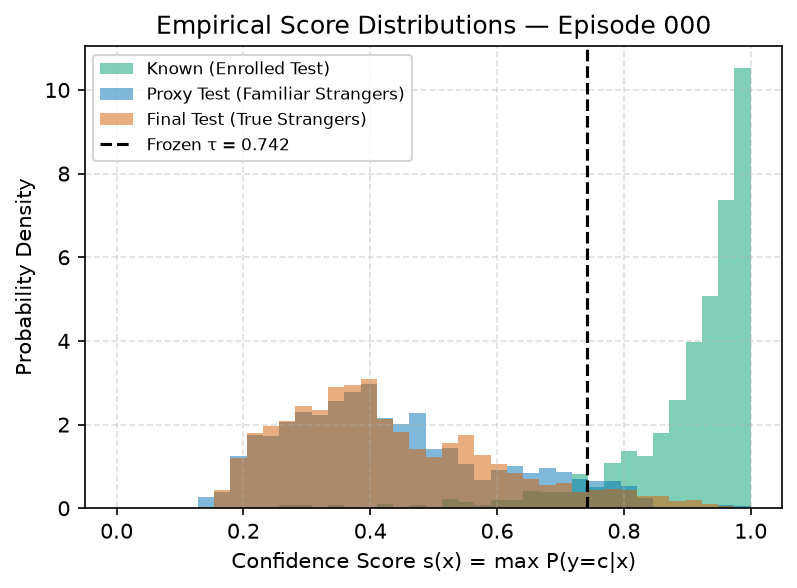

Figure 7: Proxy-Count Scaling Sweep


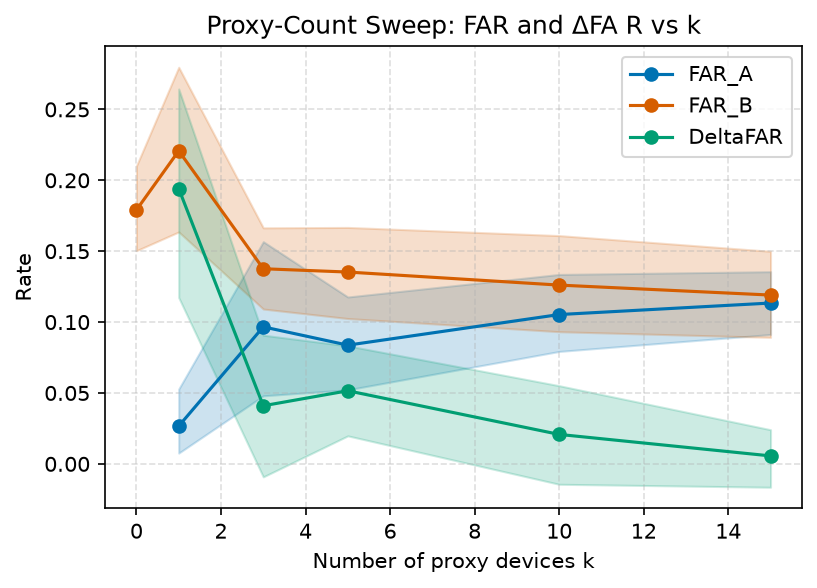

Figure 9: Security-Availability Trade-Off


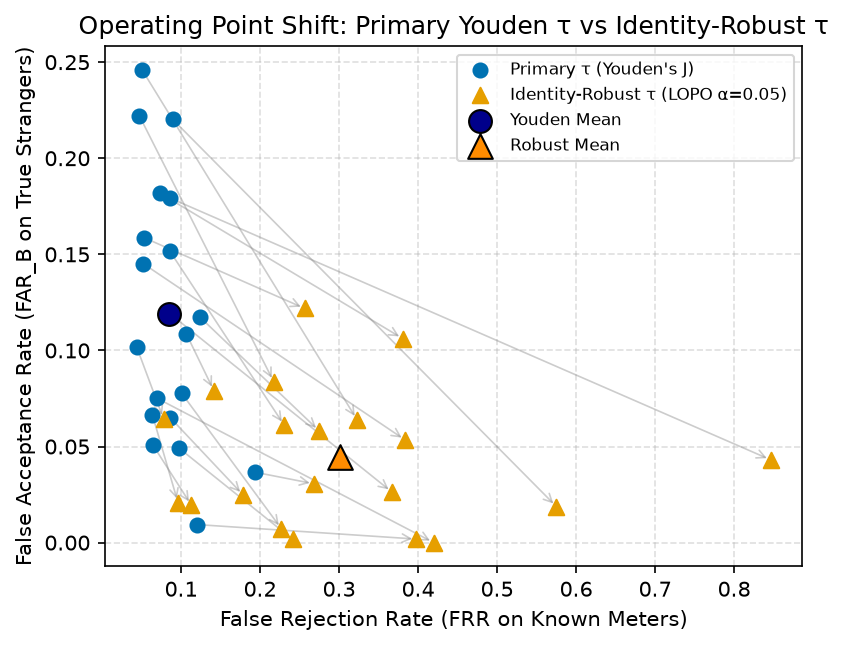

In [7]:
print("Figure 4: Empirical Decision Score Distributions")
display(Image(filename='../results/figures/fig4_score_distributions.png'))

print("Figure 7: Proxy-Count Scaling Sweep")
display(Image(filename='../results/figures/fig7_sweep_plot.png'))

print("Figure 9: Security-Availability Trade-Off")
display(Image(filename='../results/figures/fig9_tradeoff.png'))

### 7. Multi-Packet Burst Decision Fusion (L in {1, 3, 5})

In operational AMR networks, smart meters transmit periodic readings or short retry bursts. Averaging confidence over consecutive frames cancels instantaneous channel noise and sharpens the persistent physical fingerprint.


=== MULTI-PACKET BURST DECISION FUSION (20 EPISODES) ===


,burst_length,FAR_A,FAR_B,FRR,DeltaFAR,AUROC
0,1,0.113422,0.119046,0.084860,0.005624,0.948982
1,3,0.099528,0.112182,0.043740,0.012653,0.964244
2,5,0.088125,0.104538,0.035369,0.016413,0.966964


Figure 10: Multi-Packet Burst Decision Fusion


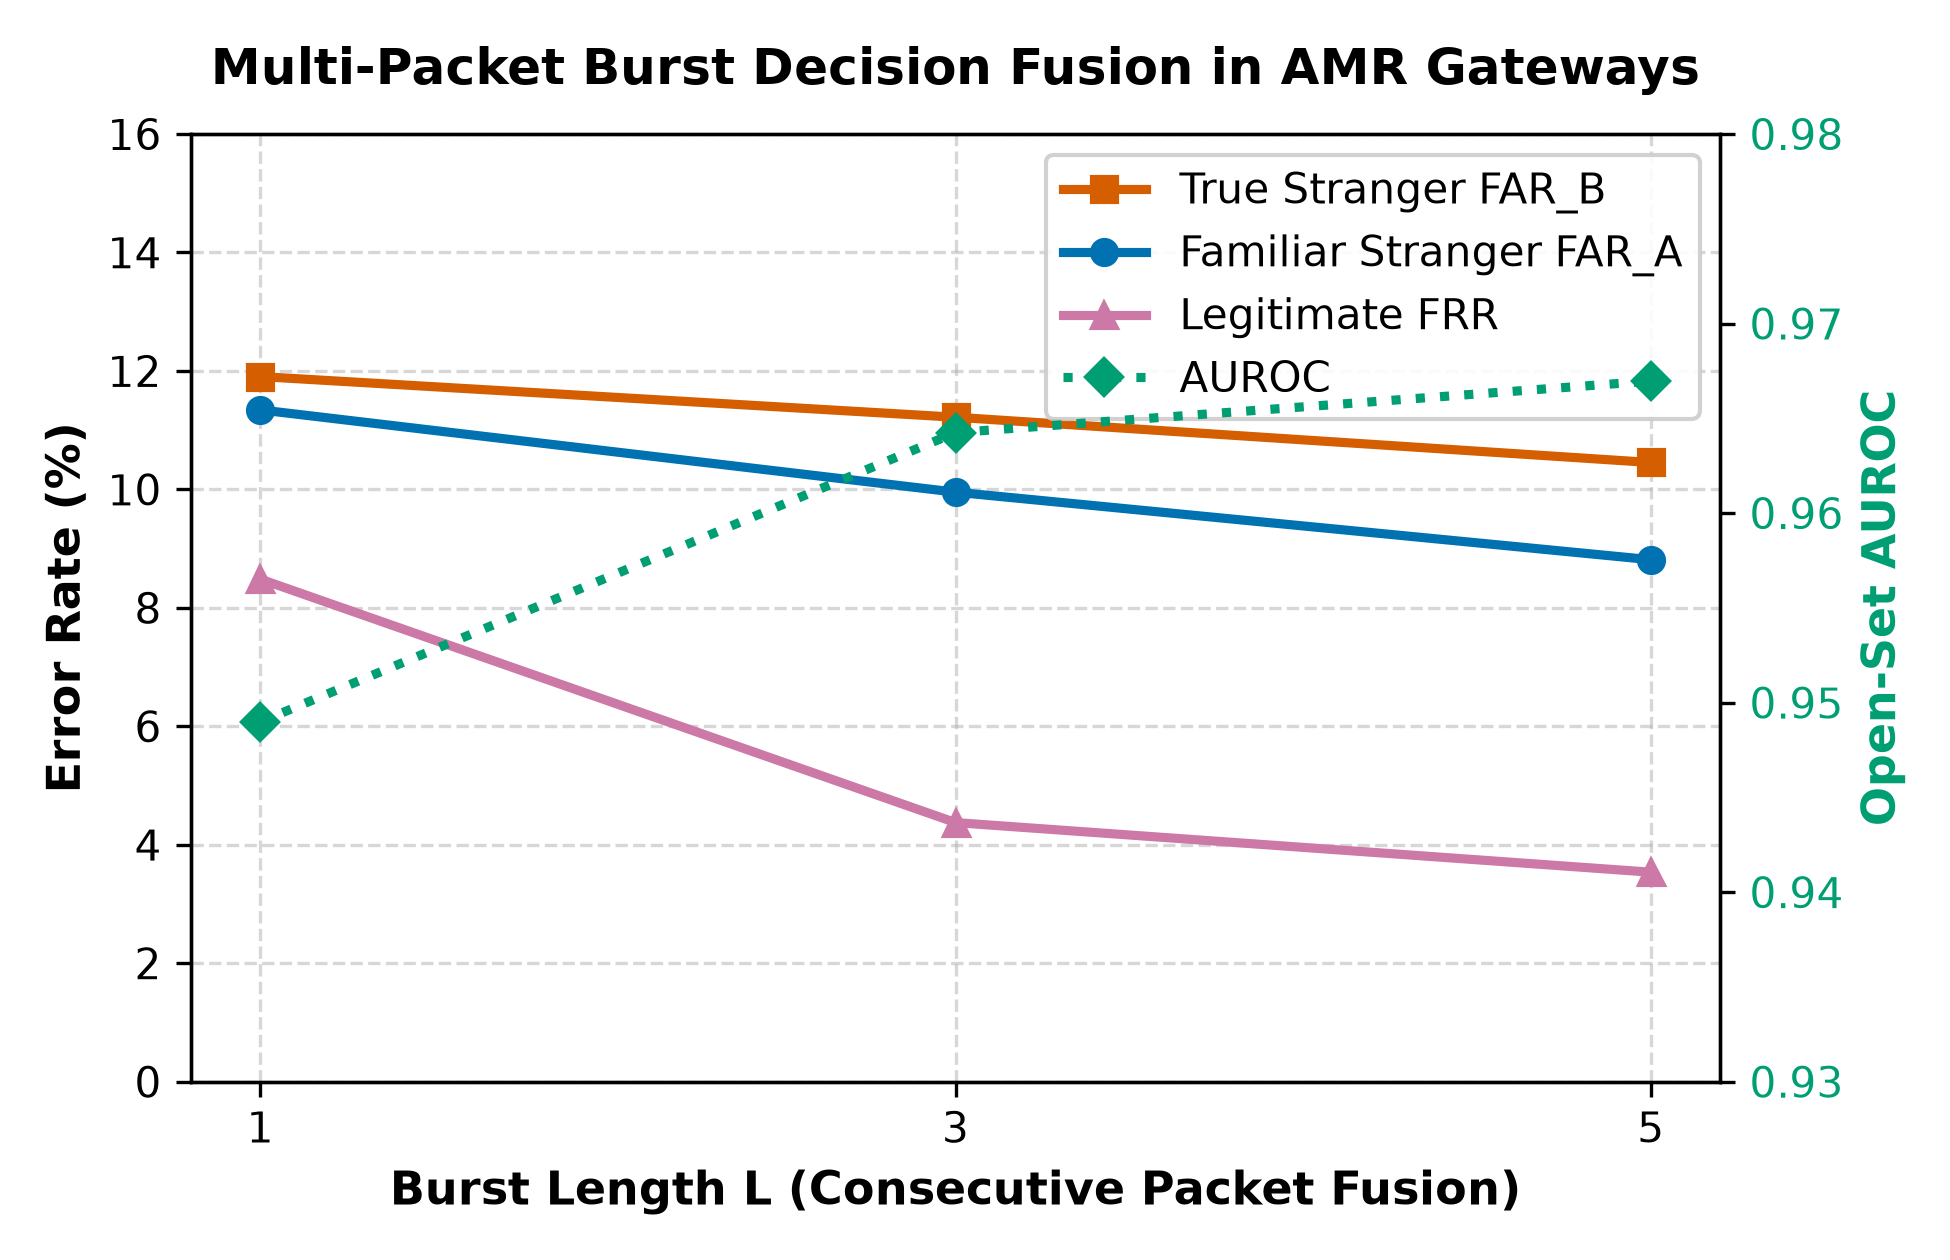

In [8]:
df_burst = pd.read_csv('../results/tables/burst_aggregation_summary.csv')
print("=== MULTI-PACKET BURST DECISION FUSION (20 EPISODES) ===")
display(df_burst)

print("Figure 10: Multi-Packet Burst Decision Fusion")
display(Image(filename='../results/figures/fig10_burst_aggregation.png'))
